# Knowing When to Defer: An Ordinal Evidential Involution–Attention Network for Calibrated Knee Osteoarthritis Grading

## 04 — Knowing *when to defer*

**This is the paper's main result.**


**The hypothesis.** Definite OA is KL ≥ 2, i.e. the $y>1$ boundary. The ordinal head carries a
separate Beta posterior per boundary, so we can use either:

- $u_{\rm cls}$ — the average over all four boundaries (pooled)
- $u_{\rm ref} = u_1$ — uncertainty at the boundary that decides the call (targeted)

A knee uncertain between KL2 and KL3 is called definite OA either way — the ambiguity changes
nothing. A knee uncertain between KL1 and KL2 sits on the decision itself, and that is the call
published studies show readers disagree on most. Pooled uncertainty blurs the two; the targeted
quantity separates them.

Both signals are applied to the **same predictions**, so any difference comes from the deferral
rule alone.

### Setup

Mount Drive so results survive a disconnect, then load the module.

In [ ]:
# --- Colab bootstrap: run this first in every notebook ---------------------
import os, sys, glob, shutil

IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = True        # True = results survive a disconnect. False = faster, but temporary.

if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = "/content/drive/MyDrive/EvIA_Knee"
elif IN_COLAB:
    PROJECT = "/content/EvIA_Knee"
else:
    PROJECT = os.path.abspath(".")

os.makedirs(PROJECT, exist_ok=True)
sys.path.insert(0, PROJECT)          # so `import evia_knee` finds the module written by 00
CACHE = os.path.join(PROJECT, "cache")
print("project:", PROJECT)

Mounted at /content/drive
project: /content/drive/MyDrive/EvIA_Knee


In [ ]:
import tensorflow as tf
gpus = tf.config.list_physical_devices("GPU")
print("TF", tf.__version__, "| GPU:", len(gpus))
if not gpus:
    print("  !! No GPU. Runtime > Change runtime type > T4 GPU, then re-run.")

TF 2.21.0 | GPU: 1


In [ ]:
import os, sys, json, time
import numpy as np, pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

import evia_knee as E
assert hasattr(E.Config(), "lr_schedule"), \
    "Old evia_knee.py loaded. Run 00_core, then Runtime > Restart session."
print("evia_knee:", E.__file__, "| lr schedule", E.Config().lr_schedule)
import evia_viz as V                 # figure style, written by notebook 00
V.use()                # written by notebook 00, found via PROJECT on sys.path
from evia_knee import Config

if IN_COLAB and not os.path.isdir("/content/knee"):
    !pip -q install kaggle
    E.download_kaggle("knee", "/content/knee")
root = E.find_dataset("knee")
print("knee data at:", root)
for d in sorted({os.path.dirname(p)
                 for p in glob.glob(root + "/**/*.png", recursive=True)}):
    print(f"  {os.path.basename(d):14s} {len(glob.glob(d + '/*.png')):5d} images")
print("\nKL1 vs KL2 is the boundary that decides definite OA, and the one "
      "readers disagree on most.")

print("task      :", "knee OA, Kellgren-Lawrence grade 0-4")
print("grades    :", E.GRADE_NAMES)
print("decision  : KL >=", E.OA_THRESHOLD, "=", E.OA_NAME)

# One config object drives everything. Changing a field here changes the experiment.
CFG = Config(
    img_size=224,                  # the radiographs are native ~224 px; upsampling adds nothing
    preprocess="clahe",
    backbone="densenet121",        # full ImageNet DenseNet-121 + EvIA side branch
    widths=(256, 320),             # EvIA branch blocks at 14x14 and 7x7
    global_branch="window",        # EvIA-W
    gate="vacuity",                # parameter-free gate
    operator="evi",
    head="ordinal",
    epochs=60,                     # cosine schedule: every run trains exactly 60 epochs
    batch_size=32,                 # 224 px radiographs leave room for a large batch
    seeds=(42, 43, 44, 45, 46),    # set to (42,) for a quick first pass
    out_dir=os.path.join(PROJECT, "results"),
)
os.makedirs(CFG.out_dir, exist_ok=True)
print("results ->", CFG.out_dir)

evia_knee: /content/drive/MyDrive/EvIA_Knee/evia_knee.py | lr schedule cosine
kaggle datasets download -d shashwatwork/knee-osteoarthritis-dataset-with-severity -p /content/knee
unzipping knee-osteoarthritis-dataset-with-severity.zip
registered DATA_ROOTS['knee'] = /content/knee
knee data at: /content/knee
  0                604 images
  1                275 images
  2                403 images
  3                200 images
  4                 44 images
  0                639 images
  1                296 images
  2                447 images
  3                223 images
  4                 51 images
  0               2286 images
  1               1046 images
  2               1516 images
  3                757 images
  4                173 images
  0                328 images
  1                153 images
  2                212 images
  3                106 images
  4                 27 images

KL1 vs KL2 is the boundary that decides definite OA, and the one readers disagree on most.


In [ ]:
P, U, UR = [], [], []
for s in CFG.seeds:
    z = np.load(os.path.join(CFG.out_dir, f"preds_eviakl_seed{s}.npz"))
    P.append(z["p"]); U.append(z["u"]); UR.append(z["ur"]); Yte = z["y"]
P, U, UR = np.stack(P), np.stack(U), np.stack(UR)
print(f"{P.shape[0]} seeds | {len(Yte)} images | definite OA {(Yte>=2).mean():.1%}")

5 seeds | 1656 images | definite OA 43.5%


### 1. The deferral curve

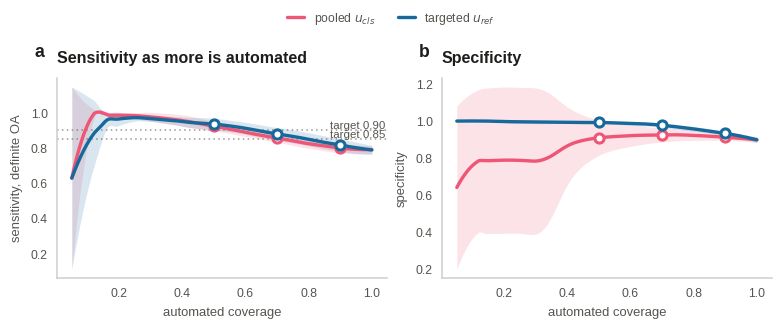

'/content/drive/MyDrive/EvIA_Knee/results/fig_deferral.png'

In [ ]:
fig, ax = V.figure(1, 2, height=2.9)
for sig, color, lab in [(U,  V.POOLED,   "pooled $u_{cls}$"),
                        (UR, V.TARGETED, "targeted $u_{ref}$")]:
    cs = [E.deferral_curve(P[s], sig[s], Yte) for s in range(P.shape[0])]   # same predictions
    cov = [np.asarray(c.coverage, float) for c in cs]
    V.seed_curves(ax[0], cov, [np.asarray(c.sensitivity, float) for c in cs], color, lab,
                  markers_at=[0.5, 0.7, 0.9])
    V.seed_curves(ax[1], cov, [np.asarray(c.specificity, float) for c in cs], color, lab,
                  markers_at=[0.5, 0.7, 0.9])

for t in (0.85, 0.90):                           # stated operating requirements
    V.ref_line(ax[0], y=t, text=f"target {t:.2f}")
ax[0].set(xlabel="automated coverage", ylabel="sensitivity, definite OA",
          title="Sensitivity as more is automated")
ax[1].set(xlabel="automated coverage", ylabel="specificity", title="Specificity")
for a in ax:
    a.spines["left"].set_visible(True)
V.fig_legend(fig, ax[0])
V.panel_letters(ax)
V.save(fig, "fig_deferral", CFG.out_dir)

### 2. Headline numbers

In [ ]:
rows = []
for s in range(P.shape[0]):
    # both signals scored against the SAME predictions P[s]
    t = E.deferral_table(P[s], {"pooled u_cls": U[s], "targeted u_ref": UR[s]}, Yte)
    t["seed"] = CFG.seeds[s]; rows.append(t)
REF = pd.concat(rows, ignore_index=True)
REF.to_csv(os.path.join(CFG.out_dir, "deferral.csv"), index=False)

print("AUTOMATED COVERAGE AT TARGET SENSITIVITY")
print(REF.groupby("signal")[["coverage_at_sens85","coverage_at_sens90",
                             "aurc_oa","sens_full_coverage"]]
         .agg(["mean","std"]).round(3).to_string())

a = REF[REF.signal == "targeted u_ref"].sort_values("seed")
b = REF[REF.signal == "pooled u_cls"].sort_values("seed")
print("\ntargeted minus pooled (paired over seeds)")
for m in ["coverage_at_sens85", "coverage_at_sens90", "aurc_oa"]:
    d, p, dz = E.paired(a[m].values, b[m].values)
    print(f"  {m:20s} {d:+.3f}   p={p:.4f}   d_z={dz:+.2f}")
print(f"\n  n={len(CFG.seeds)} -> detectable |d_z| >= {E.mde(len(CFG.seeds)):.2f}")

AUTOMATED COVERAGE AT TARGET SENSITIVITY
               coverage_at_sens85        coverage_at_sens90        aurc_oa        sens_full_coverage       
                             mean    std               mean    std    mean    std               mean    std
signal                                                                                                     
pooled u_cls                0.708  0.086              0.542  0.111   0.073  0.024              0.792  0.027
targeted u_ref              0.786  0.117              0.630  0.141   0.046  0.016              0.792  0.027

targeted minus pooled (paired over seeds)
  coverage_at_sens85   +0.078   p=0.1048   d_z=+0.93
  coverage_at_sens90   +0.088   p=0.0175   d_z=+1.74
  aurc_oa              -0.027   p=0.0384   d_z=-1.36

  n=5 -> detectable |d_z| >= 1.68


### 3. The reverse reading

Fixing coverage and reading off sensitivity answers the question a commissioner actually asks:
*"if we can review 20% by hand, how safe is the rest?"*

In [ ]:
rows = []
for s in range(P.shape[0]):
    cp = E.deferral_curve(P[s], U[s], Yte); ct = E.deferral_curve(P[s], UR[s], Yte)
    for cov in (0.5, 0.6, 0.7, 0.8, 0.9, 1.0):
        rows.append(dict(seed=CFG.seeds[s], coverage=cov,
                         pooled=E.sensitivity_at_coverage(cp, cov),
                         targeted=E.sensitivity_at_coverage(ct, cov)))
print("SENSITIVITY AT FIXED AUTOMATED COVERAGE")
print(pd.DataFrame(rows).groupby("coverage")[["pooled","targeted"]]
        .agg(["mean","std"]).round(3).to_string())
print("\nRead a row as: the model grades this share; on those it catches this much definite OA.")

SENSITIVITY AT FIXED AUTOMATED COVERAGE
         pooled        targeted       
           mean    std     mean    std
coverage                              
0.5       0.927  0.030    0.939  0.037
0.6       0.885  0.026    0.909  0.040
0.7       0.853  0.029    0.878  0.041
0.8       0.823  0.029    0.849  0.039
0.9       0.799  0.031    0.818  0.038
1.0       0.792  0.027    0.792  0.027

Read a row as: the model grades this share; on those it catches this much definite OA.


### 4. Is the gain real?

If the two signals rank cases almost identically, the difference is noise. The cases they
disagree on should be concentrated at grades 1–2 — the boundary itself.

In [ ]:
from scipy import stats as st
rows = []
for s in range(P.shape[0]):
    k = int(0.2 * len(Yte))                      # top 20% most uncertain under each rule
    top_p = set(np.argsort(-U[s])[:k])
    top_t = set(np.argsort(-UR[s])[:k])
    only_t = np.array(sorted(top_t - top_p))     # referred by targeted, kept by pooled
    rows.append(dict(seed=CFG.seeds[s],
                     spearman=st.spearmanr(U[s], UR[s])[0],
                     jaccard_top20=len(top_p & top_t) / len(top_p | top_t),
                     n_only_targeted=len(only_t),
                     frac_grade_1or2=float(np.isin(Yte[only_t], [1,2]).mean()) if len(only_t) else np.nan))
MECH = pd.DataFrame(rows)
print(MECH.round(3).to_string(index=False))
print("\nHigh frac_grade_1or2 => the extra deferrals are boundary cases: the mechanism, "
      "not a rescaling artefact.")

 seed  spearman  jaccard_top20  n_only_targeted  frac_grade_1or2
   42     0.054          0.066              290            0.779
   43     0.783          0.478              117            0.880
   44     0.567          0.244              201            0.836
   45     0.775          0.547               97            0.804
   46     0.798          0.388              146            0.815

High frac_grade_1or2 => the extra deferrals are boundary cases: the mechanism, not a rescaling artefact.


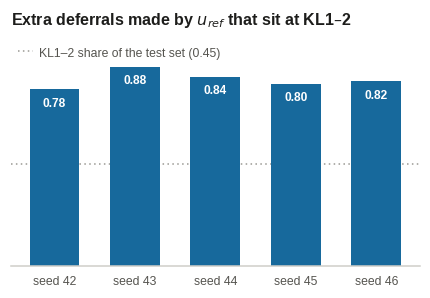

Above the dotted line = the targeted rule concentrates on the decision boundary.


In [ ]:
base = float(np.isin(Yte, [1, 2]).mean())       # what a random pick would give
fig, ax = V.figure(1, 1, width=3.8, height=2.6)
V.bars(ax, range(len(MECH)), MECH.frac_grade_1or2.values, colors=V.TARGETED,
       labels=[f"seed {s}" for s in MECH.seed], value_fmt="{:.2f}", ylim=(0, 1),
       values_inside=True)
V.ref_line(ax, y=base, label=f"KL1–2 share of the test set ({base:.2f})")
ax.set(title="Extra deferrals made by $u_{ref}$ that sit at KL1–2")
V.legend(ax, loc="upper left")
V.save(fig, "fig_boundary_mechanism", CFG.out_dir)
print("Above the dotted line = the targeted rule concentrates on the decision boundary.")

### 4b. Deferral against the CNN baselines

The same rule applied to every model on the seeds they share (42–44): a baseline defers its least confident knees (one minus the maximum recalibrated probability). Paired over seeds, Holm-corrected across baselines.

In [ ]:
from scipy import stats as st
rows = []
for s in (42, 43, 44):
    z = np.load(os.path.join(CFG.out_dir, f"preds_eviakl_seed{s}.npz"))
    t = E.deferral_table(z["p"], {"O-EvIA targeted u_ref": z["ur"], "O-EvIA pooled u_cls": z["u"]}, Yte)
    t["seed"] = s; rows.append(t)
    for name in ["densenet121", "resnet50", "efficientnetb0", "mobilenetv3s"]:
        zb = np.load(os.path.join(CFG.out_dir, f"preds_{name}_seed{s}.npz"))
        t = E.deferral_table(zb["p"], {name: zb["u"]}, Yte); t["seed"] = s; rows.append(t)
DB = pd.concat(rows, ignore_index=True)
DB.to_csv(os.path.join(CFG.out_dir, "deferral_vs_baselines.csv"), index=False)
print("DEFERRAL, seeds 42-44 (mean ± SD)")
print(DB.groupby("signal")[["sens_full_coverage", "coverage_at_sens85", "coverage_at_sens90", "aurc_oa"]]
        .agg(["mean", "std"]).round(3).to_string())

ours = DB[DB.signal == "O-EvIA targeted u_ref"].sort_values("seed")
cmp = []
for name in ["densenet121", "resnet50", "efficientnetb0", "mobilenetv3s"]:
    b = DB[DB.signal == name].sort_values("seed")
    for m in ["coverage_at_sens90", "coverage_at_sens85", "aurc_oa"]:
        d, p, dz = E.paired(ours[m].values, b[m].values)
        cmp.append(dict(vs=name, metric=m, delta=d, p=p, dz=dz))
CMPB = pd.DataFrame(cmp)
for m, g in CMPB.groupby("metric"):
    rej, adj = E.holm(g.p.values); CMPB.loc[g.index, "p_holm"] = adj; CMPB.loc[g.index, "sig"] = rej
CMPB.to_csv(os.path.join(CFG.out_dir, "deferral_vs_baselines_tests.csv"), index=False)
print("\nO-EvIA (targeted) minus baseline, paired over seeds 42-44:")
print(CMPB.round(4).to_string(index=False))
print(f"\nn=3 -> detectable |d_z| >= {E.mde(3):.2f}")

DEFERRAL, seeds 42-44 (mean ± SD)
                      sens_full_coverage        coverage_at_sens85        coverage_at_sens90        aurc_oa       
                                    mean    std               mean    std               mean    std    mean    std
signal                                                                                                            
O-EvIA pooled u_cls                0.803  0.002              0.700  0.085              0.561  0.042   0.072  0.026
O-EvIA targeted u_ref              0.803  0.002              0.830  0.049              0.683  0.064   0.039  0.003
densenet121                        0.829  0.033              0.935  0.056              0.846  0.051   0.062  0.004
efficientnetb0                     0.770  0.014              0.813  0.037              0.594  0.014   0.071  0.005
mobilenetv3s                       0.750  0.014              0.740  0.028              0.586  0.049   0.086  0.006
resnet50                           0.785  0.01

### 5. Clinical summary

In [ ]:
tg = REF[REF.signal == "targeted u_ref"]; pl = REF[REF.signal == "pooled u_cls"]
summary = pd.DataFrame([
    ("Sensitivity with no deferral",        f"{tg.sens_full_coverage.mean():.3f} ± {tg.sens_full_coverage.std():.3f}"),
    ("Coverage @ 85% sensitivity (targeted)", f"{tg.coverage_at_sens85.mean():.3f} ± {tg.coverage_at_sens85.std():.3f}"),
    ("Coverage @ 90% sensitivity (targeted)", f"{tg.coverage_at_sens90.mean():.3f} ± {tg.coverage_at_sens90.std():.3f}"),
    ("Coverage @ 90% sensitivity (pooled)",   f"{pl.coverage_at_sens90.mean():.3f} ± {pl.coverage_at_sens90.std():.3f}"),
    ("Human workload @ 90% target",           f"{1-tg.coverage_at_sens90.mean():.1%} of images"),
], columns=["quantity", "value"])
summary.to_csv(os.path.join(CFG.out_dir, "deferral_headline.csv"), index=False)
print(summary.to_string(index=False))

                             quantity           value
         Sensitivity with no deferral   0.792 ± 0.027
Coverage @ 85% sensitivity (targeted)   0.786 ± 0.117
Coverage @ 90% sensitivity (targeted)   0.630 ± 0.141
  Coverage @ 90% sensitivity (pooled)   0.542 ± 0.111
          Human workload @ 90% target 37.0% of images


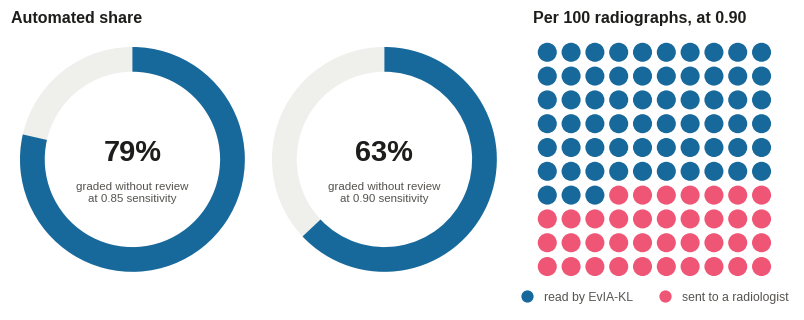

'/content/drive/MyDrive/EvIA_Knee/results/fig_deferral_headline.png'

In [ ]:
cov90 = float(tg.coverage_at_sens90.mean()); cov85 = float(tg.coverage_at_sens85.mean())
fig, ax = V.figure(1, 3, width=7.2, height=2.7)
V.donut(ax[0], cov85, V.AUTO, sub="graded without review\nat 0.85 sensitivity")
ax[0].set_title("Automated share")
V.donut(ax[1], cov90, V.AUTO, sub="graded without review\nat 0.90 sensitivity")
ax[1].set_title(" ")
n_auto = int(round(100 * cov90))
V.waffle(ax[2], [n_auto, 100 - n_auto], [V.AUTO, V.DEFER],
         names=["read by O-EvIA", "sent to a radiologist"])
ax[2].set_title("Per 100 radiographs, at 0.90")
V.save(fig, "fig_deferral_headline", CFG.out_dir)